In [1]:
# Copyright (C) 2026 Advanced Micro Devices, Inc. All rights reserved.
#
# SPDX-License-Identifier: BSD-3-Clause
#
# Portions of this file consist of AI-generated content. AI-assisted
# content has been reviewed and validated by the authors.

# A digital twin of the SO-101, from first principles

A digital twin is only useful if code cannot tell it from the robot. That
reduces to three claims, each checked below with a measurement:

1. **It moves like the arm** - same command interface, same servo dynamics.
2. **It sees like the arm** - a camera rendered where the real one is mounted.
3. **It feels like the arm** - gripper current that comes from contact.

Then the payoff: the twin console of `./run_pipeline.sh --digital-twin`, with
voice control - you speak, and the workshop's own behaviors drive the twin.

What is simulated: the arm, its servos, the wrist camera and the table
scene (MuJoCo). What is real: everything above the arm transport - your
webcam and microphone, YOLOv26s pose and detection, MediaPipe Hands, the
mapper, Whisper, the Llama intent parser and the behaviors. Everything but
llama-server runs inside this kernel; ROS 2 is not needed.

In [2]:
import os, sys, pathlib, threading, time, warnings

os.environ.setdefault("MUJOCO_GL", "egl")  # headless rendering on the iGPU; set before mujoco loads
warnings.filterwarnings("ignore", message="Unable to import Axes3D.*", category=UserWarning)

PROJECT = (pathlib.Path.cwd() / ".." / ".." / "solution").resolve()
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

import cv2, numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from jupyter_ui_poll import ui_events

from common.config import load_config

cfg = load_config()
cfg["robot"]["backend"] = "sim"  # the MuJoCo twin instead of the Feetech bus
cfg["robot"]["use_ros2"] = False  # in-process: this kernel owns the (simulated) bus
cfg["cameras"]["operator"]["use_ros2"] = False  # and reads the webcam itself - no ROS 2 needed
LOAD_THRESHOLD = 120  # Present_Current counts the grip behavior treats as contact

## 0. A body

The twin starts as a physics model: the SO-101's links, joints and
actuators (the open MJCF model), on a table with a few objects. MuJoCo
steps it 500 times per second on a CPU thread, locked to wall-clock time -
so one second of waiting is one second of simulated motion.

In [3]:
from common.motion import sim_world

world = sim_world(cfg)
m = world.model
print(f"{m.nbody} bodies, {m.njnt} joints, {m.nu} actuators, timestep {world.dt * 1000:.0f} ms")
print("detectable objects:", world.objects)

t0, w0 = world.time, time.perf_counter()
time.sleep(1.0)
print(f"sim time advanced {world.time - t0:.3f} s in {time.perf_counter() - w0:.3f} s of wall time")

18 bodies, 10 joints, 6 actuators, timestep 2 ms
detectable objects: ['book', 'sports_ball', 'bottle', 'toothbrush']
sim time advanced 0.998 s in 1.000 s of wall time


## 1. It moves like the arm

`make_arm_backend(cfg)` returns `SimArmClient`, a subclass of the real
`LeRobotArm` in which only the LeRobot `SO101Follower` is swapped for a
simulated bus. Joint clamping, the goal-speed/acceleration register writes
and the current readback all run through the same code as on the rig.

Below the bus sits the part that matters physically: an STS3215 servo does
not jump to a goal. Its firmware accelerates, cruises and decelerates (a
trapezoidal profile), and the twin's servo model does the same. Command one
60° step and measure what comes back.

SimArmClient is a LeRobotArm: True
at rest: {'shoulder_pan': 0.0, 'shoulder_lift': -96.5, 'elbow_flex': 96.0, 'wrist_flex': 22.5, 'wrist_roll': 86.8, 'gripper': 38.0}
peak speed 96 deg/s, 95% of the step after 0.77 s


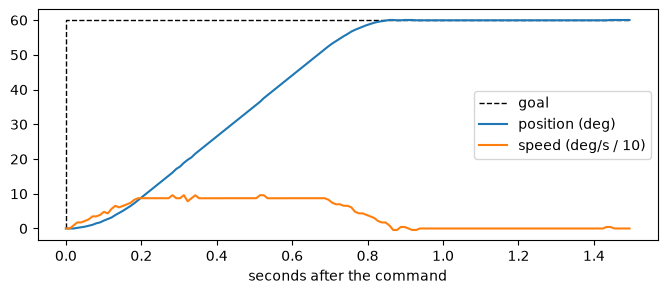

In [4]:
from common.motion import LeRobotArm, make_arm_backend

arm = make_arm_backend(cfg)
print(f"{type(arm).__name__} is a LeRobotArm: {isinstance(arm, LeRobotArm)}")
print("at rest:", {k: round(v, 1) for k, v in arm.get_joints().items()})


def step_response(joint, delta, seconds=1.5, hz=100):
    """Send one goal, then sample the joint - what a scope on the servo would show."""
    q0 = arm.get_joints()[joint]
    arm.send_joints({joint: q0 + delta})
    t, q, t0 = [], [], time.perf_counter()
    while (now := time.perf_counter() - t0) < seconds:
        t.append(now)
        q.append(arm.get_joints()[joint])
        time.sleep(1.0 / hz)
    return np.array(t), np.array(q) - q0


t, q = step_response("shoulder_pan", 60.0)
v = np.gradient(q, t)
t95 = t[np.argmax(q >= 0.95 * 60.0)]
print(f"peak speed {v.max():.0f} deg/s, 95% of the step after {t95:.2f} s")

fig, ax = plt.subplots(figsize=(8, 3))
ax.step([0, 0, t[-1]], [0, 60, 60], "k--", lw=1, where="post", label="goal")
ax.plot(t, q, label="position (deg)")
ax.plot(t, v / 10, label="speed (deg/s / 10)")
ax.set_xlabel("seconds after the command")
ax.legend()
plt.show()
arm.go_to_rest()

## 2. It sees like the arm

A camera is a pinhole at a pose. The twin's `wrist_cam` sits where the real
arm camera is mounted - beside the gripper, looking along the jaws - so it
moves with the wrist and sees what is being gripped. A render thread draws
every camera on the iGPU (EGL), separate from the physics thread, and
`SimCamera.read()` returns `(ok, bgr)` exactly like `cv2.VideoCapture`.

Present the open jaws, put the toothbrush between them, and look from both
the wrist and a free 3D view.

renderer: AMD Radeon Graphics (radeonsi, gfx1151, LLVM 20.1.2, DRM 3.64, 7.0.0-38-generic)


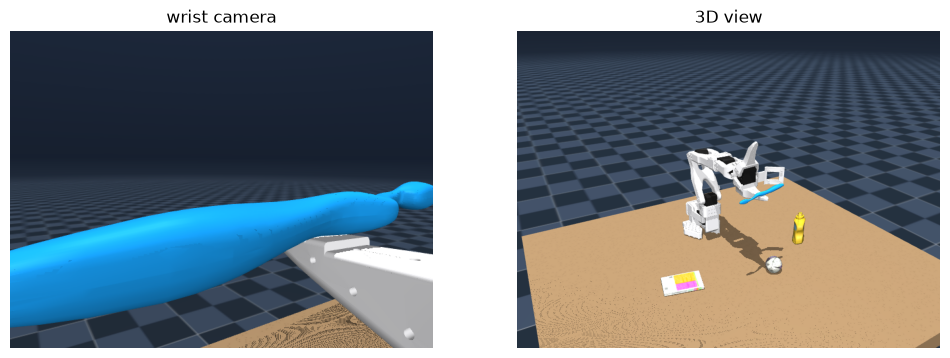

In [5]:
from so101_sim import SimCamera
from so101_sim.render import shared_renderer

PRESENT = {"shoulder_pan": 0.0, "shoulder_lift": -35.0, "elbow_flex": 30.0, "wrist_flex": 10.0, "wrist_roll": 0.0}

wrist = SimCamera(world, "arm")  # the arm camera, on the wrist
view = SimCamera(world, "view", width=800, height=600)  # a free 3D view, for us

arm.go_to({**PRESENT, "gripper": 85.0})
time.sleep(1.0)  # let the jaws finish opening
world.stage_object("toothbrush", PRESENT)
_, w_img = wrist.read(fresh=True)
_, v_img = view.read(fresh=True)
print("renderer:", shared_renderer(world).renderer)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, img, title in zip(axes, (w_img, v_img), ("wrist camera", "3D view")):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 3. It feels like the arm

The real gripper has no touch sensor. The grip behavior infers contact from
the servo's `Present_Current`: closing on nothing, the motor reaches its
goal and the current falls away; closing on an object, the jaws stall and
the motor pushes against it, so the current stays high.

The twin produces that current from the physics - the actuator effort the
contact actually demands - not from a script. Close the jaws twice, once
empty and once on the toothbrush, and compare against the threshold.

peak current - empty jaws: 92   toothbrush: 216   (threshold 120)


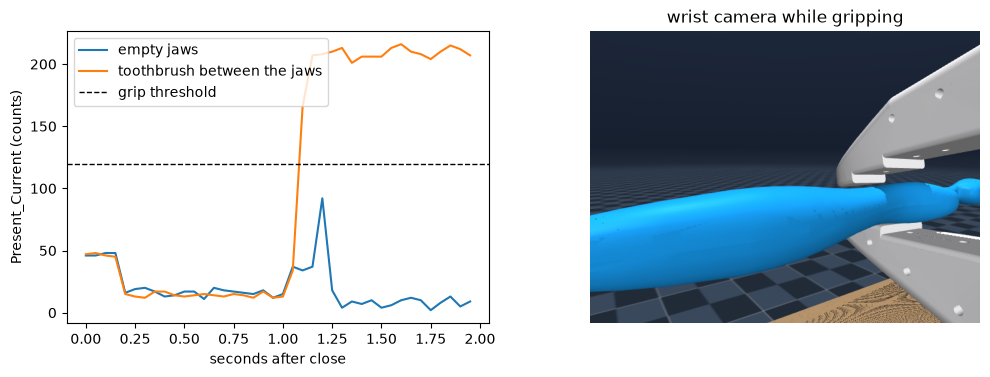

In [6]:
from common.motion import GRIPPER_CLOSED_FLOOR


def squeeze(with_object, seconds=2.0, hz=20):
    """Open at PRESENT, optionally place the toothbrush, then return the current trace."""
    arm.go_to({**PRESENT, "gripper": 85.0})
    time.sleep(1.0)
    if with_object:
        world.stage_object("toothbrush", PRESENT)
    else:
        world.hide("toothbrush")
    arm.send_joints({"gripper": GRIPPER_CLOSED_FLOOR})
    trace = []
    for _ in range(int(seconds * hz)):
        time.sleep(1.0 / hz)
        trace.append(arm.get_gripper_load() or 0.0)
    _, img = wrist.read(fresh=True)
    arm.go_to({"gripper": 85.0})  # let go
    return np.array(trace), img


empty, _ = squeeze(with_object=False)
held, held_view = squeeze(with_object=True)
print(f"peak current - empty jaws: {empty.max():.0f}   toothbrush: {held.max():.0f}   (threshold {LOAD_THRESHOLD})")

fig, (ax, ax_img) = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(len(held)) / 20
ax.plot(t, empty, label="empty jaws")
ax.plot(t, held, label="toothbrush between the jaws")
ax.axhline(LOAD_THRESHOLD, color="k", ls="--", lw=1, label="grip threshold")
ax.set_xlabel("seconds after close")
ax.set_ylabel("Present_Current (counts)")
ax.legend()
ax_img.imshow(cv2.cvtColor(held_view, cv2.COLOR_BGR2RGB))
ax_img.set_title("wrist camera while gripping")
ax_img.axis("off")
plt.show()
world.place("toothbrush", world.model.body("toothbrush").pos)  # back on the table
arm.go_to_rest()

## 4. Control the digital twin

The twin moves, sees and feels like the arm, so the workshop's behaviors can
drive it without knowing. Here you control it by voice, or by typing, exactly
as `./run_pipeline.sh --digital-twin` does: Whisper turns what you say into
text, Llama picks one command, and the behavior registered for that command
runs on the twin.

The commands are the pipeline's, from
[Voice commands → behaviors](../../../README.md#voice-commands--behaviors) in
the top-level `README.md`:

| Say something like | Intent | What happens |
|---|---|---|
| "mirror my arm", "copy my movements" | `gesture_mimic` | YOLO-pose tracks your wrist; a direct camera-frame mapping drives the arm joints to follow your hand (depth from MediaPipe hand size). MediaPipe tracks your thumb–index pinch → gripper. |
| "pick up the ball", "grab the bottle", "pick up the book", "pick up the toothbrush" | `pick_place` | YOLO-detect grounds the named object on the arm camera → pan-servo onto it → locate it on the table from its box → IK reach, straight down onto it → feedback grasp, checked after the lift → find you with YOLO-pose → hand it over. |
| "fetch the block" | `fetch_block` | Legacy fixed-pose behavior: approach the taught spot → grasp → lift → find you (YOLO-pose) → extend → release → home. It does not use object detection. |
| "hold this", "take this toothbrush" | `grip` | Closes until contact (current/stall + grace window), confirms with the arm camera, then **locks the grip**. A following `gesture_mimic` keeps the lock while carrying the object. Saying "grip" again releases. |
| "dance", "show me some moves" | `dance` | BPM-paced keyframe choreography. |
| "wave at me", "say hi" | `wave` | Raises the arm and waves `behaviors.wave.cycles` times. |
| "go home", "reset position" | `home` | Returns to the rest pose. |
| "stop", "halt", "freeze" | `stop` | **Keyword-matched on the raw transcript — bypasses the LLM** and interrupts any running behavior immediately. |

Gesture mimic, dance, wave and home are your code (`integration/`); grip,
pick_place and fetch_block are provided (`common/manipulation.py`). A new
command stops the running behavior and starts the new one.

The scene's sports ball, book, bottle and toothbrush are all COCO classes
supported by YOLO26s. The arm searches the configured `scan_pans` from its
scan pose, then servos from the first matching view; a grasp that fails or
slips is reported as failed, not done.

What the console shows:

- **top row**: YOLOv26s-pose and MediaPipe Hands on your webcam, and
  YOLOv26s detection on the twin's arm camera;
- **bottom left**: the twin, moving;
- **bottom right**: microphone level, what Whisper heard, the command Llama
  picked, the running behavior, the gripper current and the joints.

YOLO runs on the NPU (CPU if the NPU is unavailable - each tile title says
which), MediaPipe on the CPU. Without a webcam a scripted person stands in,
and the cell says so. The console only watches: the tiles show the frames
and model results the running behavior used.

In [7]:
from common.fixtures import ScriptedHands, ScriptedPose, SyntheticCamera
from common.motion import mapper_from_config
from common.quiet import QuietHands, quiet_stderr
from common.twin_console import TwinConsole
from integration.dispatch import WorkshopContext
from ros.camera_client import make_camera


def perception():
    """Webcam + the three models; a scripted person if the webcam gives no frames."""
    from models.hands import HandTracker
    from models.vision import ObjectDetector, PoseEstimator

    pose, detector = PoseEstimator(cfg), ObjectDetector(cfg)
    # MediaPipe's C++ init writes to stderr (absl, EGL, TFLite). Silence that
    # here, and keep later detections quiet too.
    with quiet_stderr():
        hands = QuietHands(HandTracker(cfg))
        hands.process(np.zeros((64, 64, 3), np.uint8))
    print(f"YOLO-pose on {pose.provider}, YOLO detect on {detector.provider}, MediaPipe Hands on CPU")
    cam = make_camera(cfg, "operator")  # cameras.operator.use_ros2 is off: a direct OpenCV capture
    if cam.read()[0]:
        print(f"webcam: {cfg['cameras']['operator']['device']}")
        return cam, pose, hands, detector
    cam.close()
    print(f"webcam: no frames from {cfg['cameras']['operator']['device']} (in use by another kernel?) "
          "- a scripted person stands in")
    return SyntheticCamera(), ScriptedPose(), ScriptedHands(), detector


cam, pose, hands, detector = perception()
console = TwinConsole(
    arm,
    operator=cam,
    pose=pose,
    hands=hands,
    armcam=wrist,
    detector=detector,
    view=view,
    load_threshold=LOAD_THRESHOLD,
)
ctx = WorkshopContext(
    cfg=cfg,
    arm=arm,
    camera=console.operator,  # behaviors read the fanned-out webcam
    pose=pose,
    hands=hands,
    detector=detector,  # pick_place finds objects with it
    arm_camera=console.armcam,  # the twin's wrist camera, for grip and pick_place
    mapper=mapper_from_config(cfg),
    headless=True,  # behaviors draw into the console, never their own window
)
ctx.say = console.say  # robot speech lands in the voice panel

YOLO-pose on VitisAIExecutionProvider, YOLO detect on VitisAIExecutionProvider, MediaPipe Hands on CPU
webcam: /dev/video0


Next, the voice path. A microphone thread cuts the audio into utterances
(about 0.7 s of silence ends one) and Whisper turns each into text on the CPU
(`common/speech.py`). Every transcript then goes through *your*
`handle_transcript`: the stop fast path, the noise gate, Llama on the iGPU,
and the registry built by *your* `build_registry`.

"stop" acts the moment it is heard. Any other command is queued; if a
behavior is running, it is stopped so the newest command runs next - the
pipeline's dispatcher does the same.

Without a microphone, type commands into the box under the console; without
llama-server, a keyword stand-in routes them. The cell prints which you got.

In [8]:
import queue

from common.fixtures import offline_parse_text
from common.intents import CommandRegistry, Intent, ParsedCommand, is_noise, is_stop
from common.speech import MicListener, Whisper
from integration.dispatch import build_registry, handle_transcript


def brain():
    """Llama on the iGPU (llama-server, started if needed); the keyword stand-in if it can't come up."""
    try:
        from models.llm import LlamaIntentParser

        llm = LlamaIntentParser(cfg)
        print("intent: Llama 3.2 3B on the iGPU (grammar-constrained)")
        return llm.parse, llm
    except Exception as e:
        print(f"intent: llama-server unavailable ({e}) - the keyword stand-in routes commands")

    def keywords(text):
        d = offline_parse_text(text)
        params = {"object": d["object"]} if d.get("object") else {}
        return ParsedCommand(Intent.from_string(d["command"]), params=params, transcript=text)

    return keywords, None


parse_intent, llm = brain()


def parse(text):
    cmd = parse_intent(text)
    console.parsed(cmd)
    return cmd


behaviors = build_registry()
ctx.registry = CommandRegistry()
for intent in behaviors.intents():
    ctx.registry.add(intent, console.track(intent.value, behaviors.get(intent)))
print("voice commands:", ", ".join(i.value for i in ctx.registry.intents()), "- and stop")

commands = queue.Queue()
busy = threading.Event()  # set while a behavior runs


def on_transcript(text):
    """Every utterance, spoken or typed: a stop acts now; a new command replaces the running one."""
    if is_noise(text):  # a cough, keyboard clicks, silence: shown, never dispatched
        console.ignored(text)
        return
    console.heard(text)
    if is_stop(text):
        console.stopped()
        handle_transcript(ctx, text, parse)  # sets ctx.stop_event: the running behavior ends
        return
    commands.put(text)
    if busy.is_set():
        ctx.stop_event.set()  # the running behavior ends; the dispatcher runs the new command


whisper = Whisper(cfg)
mic = MicListener(cfg, whisper.transcribe, on_transcript, on_level=console.on_level).start()
console.transcribing = lambda: mic.transcribing
time.sleep(0.5)
if mic.error:
    console.voice = "typed"
    print(f"microphone: unavailable ({mic.error}) - type commands under the console")
else:
    print(f"microphone: listening, Whisper on {whisper.provider}")

intent: Llama 3.2 3B on the iGPU (grammar-constrained)
voice commands: gesture_mimic, dance, wave, home, grip, pick_place, fetch_block - and stop


/home/tgmeinde/GitHub/embedded-x86-ai/workshops/vvla-pipeline/.venv/lib/python3.12/site-packages/webrtcvad.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


microphone: listening, Whisper on CPU


Run the console and talk to the twin. Say **"copy my movements"** and move
your right arm: the twin follows your wrist (left/right, up/down), your reach
(forward/back), your wrist bend, the thumb-index angle (roll) and your pinch
(gripper). Try **"hold this"**, **"pick up the ball"**, **"pick up the
bottle"**, **"pick up the book"**, **"pick up the toothbrush"**, **"wave"**,
**"dance"** and **"go home"**, and **"stop"** at any time. *end session*
stops whatever is running and parks the arm; run the cell again to resume.

In [ ]:
FPS = 15


def jpeg(img):
    return cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 80])[1].tobytes()


def submit(change):
    text = change["new"].strip()
    if text:
        typed.value = ""
        on_transcript(text)


screen = widgets.Image(format="jpeg", layout=widgets.Layout(width="1200px"))
stop = widgets.Button(description="stop", button_style="danger")
typed = widgets.Text(placeholder="or type a command, then Enter", continuous_update=False,
                     layout=widgets.Layout(width="400px"))
end = widgets.Button(description="end session")
finished = threading.Event()
stop.on_click(lambda _: on_transcript("stop"))
typed.observe(submit, names="value")
end.on_click(lambda _: (finished.set(), ctx.stop_event.set()))
display(widgets.VBox([screen, widgets.HBox([stop, typed, end])]))


def dispatch_loop():
    """Behaviors run here, one at a time; a newer command replaces a queued one."""
    while not finished.is_set():
        try:
            text = commands.get(timeout=0.2)
        except queue.Empty:
            continue
        while not commands.empty():  # only the newest command runs
            text = commands.get_nowait()
        busy.set()
        try:
            handle_transcript(ctx, text, parse)
        except Exception as e:
            console.say(f"(that failed: {e})")
        finally:
            busy.clear()


console.say("Ready. Try: 'copy my movements', 'hold this', 'pick up the ball', 'pick up the bottle', "
            "'pick up the book', 'pick up the toothbrush', 'wave', 'dance', 'go home' - or 'stop'.")
dispatcher = threading.Thread(target=dispatch_loop, daemon=True)
dispatcher.start()
with ui_events() as poll:
    while not finished.is_set():
        t0 = time.perf_counter()
        poll(10)  # deliver button clicks and typed commands while this cell runs
        screen.value = jpeg(console.compose())
        time.sleep(max(0.0, 1.0 / FPS - (time.perf_counter() - t0)))
dispatcher.join(timeout=10)
arm.go_to_rest()
print("session ended, arm parked")

Ready. Try: 'copy my movements', 'hold this', 'pick up the ball', 'pick up the bottle', 'pick up the book', 'pick up the toothbrush', 'wave', 'dance', 'go home' - or 'stop'.
Looking for a boil.
Sorry - I don't know what a boil looks like.
Looking for a ball.
Got the sports ball - bringing it to you.
Done.
Place the object between the jaws.
I don't see anything between the jaws yet - closing carefully.
No object detected.
Looking for a bottle.
The grasp slipped - trying once more.
I couldn't get a grip on the bottle. Giving up for now.
Looking for a toothbrush.
The grasp slipped - trying once more.
I couldn't get a grip on the toothbrush. Giving up for now.
Looking for a book.
The grasp slipped - trying once more.
I couldn't get a grip on the book. Giving up for now.
Looking for a ball.
The grasp slipped - trying once more.
I couldn't get a grip on the sports ball. Giving up for now.
Looking for a ball.
I couldn't line up on it - grabbing where I last saw it.
The grasp slipped - trying 

## Clean up

On the full system, `python app.py --digital-twin` runs the same twin behind ROS 2:
the node supervisor starts `so101_sim.node` in place of the arm node and the
arm camera node, and the arm and camera clients talk to it over the usual
topics. `./run_pipeline.sh --digital-twin` shows this console in a desktop
window.

In [ ]:
from so101_sim import close_shared_world

finished.set()
ctx.stop_event.set()
dispatcher.join(timeout=5)
mic.stop()
if llm is not None:
    llm.close()  # stops llama-server if this notebook started it
console.close()  # the webcam and arm camera fan-outs, and the cameras they wrap
view.release()
hands.close()
arm.close()
close_shared_world()
print("twin closed")